# Visualize Layer-Averaged Diagnostics Across Context Lengths

This Visualize notebook loads the cached data produced by `Generate-layer-averaged-diagnostics-across-context-lengths.ipynb` and generates figures illustrating how layer-averaged graph-spectral diagnostics vary across context lengths for the main numerical input families using Llama-3.2-3B, as described under **Graph-Spectral Signatures of Dynamical Complexity Across Context Lengths** in the Results section of the main text. It also generates HFER cutoff-sensitivity and low-end normalized-Laplacian spectrum figures presented under **Robustness and Layerwise Consistency of Graph-Spectral Diagnostics** in the appendix.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter


In [2]:
DATA_PATH = Path("cache") / "all_diagnostics_averaged_over_layers_vs_context_length.npz"

# Load cached plotting data
with np.load(DATA_PATH, allow_pickle=False) as data:
    # Labels and context lengths
    input_names = data["input_names"].astype(str)
    context_token_counts = data["context_token_counts"].astype(int)

    # Means and standard deviations across realizations
    active_modes_mean = data["active_modes_mean"].astype(float)
    active_modes_std = data["active_modes_std"].astype(float)
    fiedler_mean = data["fiedler_mean"].astype(float)
    fiedler_std = data["fiedler_std"].astype(float)
    hfer_mean = data["hfer_mean"].astype(float)
    hfer_std = data["hfer_std"].astype(float)
    # HFER variants by high-frequency tail fraction
    hfer_tail_fractions = data["hfer_tail_fractions"].astype(float)
    hfer_tail_energy_mean = data["hfer_tail_energy_mean"].astype(float)
    hfer_tail_energy_std = data["hfer_tail_energy_std"].astype(float)

    # First nontrivial normalized-Laplacian eigenvalues
    fiedler_lsym_low_spectrum_mean = data["fiedler_lsym_low_spectrum_mean"].astype(float)
    fiedler_lsym_low_spectrum_std = data["fiedler_lsym_low_spectrum_std"].astype(float)
    fiedler_lsym_low_spectrum_lambda_indices = data[
        "fiedler_lsym_low_spectrum_lambda_indices"
    ].astype(int)



In [3]:
def _diagnostic_line_style(data_name):
    # Use consistent styles across diagnostics
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    # Draw chaotic and Lorenz curves above periodic curves
    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2
    
    style["markersize"] = 4.0
    return style


def _metric_line_style(data_name, ensemble=True):
    # Reuse the main palette for standalone metrics
    style = _diagnostic_line_style(data_name).copy()
    style["markersize"] = 4.0 if ensemble else 4.5
    return style


def _darken_color(color, factor=0.78):
    return tuple(factor * channel for channel in to_rgb(color))


def _endpoint_label_text(data_name):
    # Shorten right-edge labels
    label_map = {
        "Constant sampled": "Constant",
        "Logistic r=3.2": "Period 2",
        "Logistic r=3.5": "Period 4",
        "Logistic r=3.55": "Period 8",
        "Logistic r=3.566": "Period 16",
        "Logistic r=3.5692": "Period 32",
        "Logistic r=3.5698": "Period 64",
        "Logistic r=3.9": "r=3.9",
        "Logistic r=4.0": "r=4.0",
        "Lorenz": "Lorenz",
    }
    return label_map.get(str(data_name), str(data_name))


def _endpoint_label_offset(data_name):
    return 0.0


def _add_endpoint_label(ax, x, y, label, color, y_offset=0.0, x_offset=10.0, fontsize=8.0):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    # Skip missing endpoints
    if x.size == 0 or y.size == 0:
        return
    if not np.isfinite(x[-1]) or not np.isfinite(y[-1]):
        return
    ax.text(
        float(x[-1]) + float(x_offset),
        float(y[-1]) + float(y_offset),
        str(label),
        color=color,
        fontsize=fontsize,
        ha="left",
        va="center",
        clip_on=False,
    )


def _format_context_axis(ax, ylabel, title):
    xticks = np.arange(0, 2001, 200)
    ax.set_xticks(xticks)
    ax.set_xlim(0, 2080)
    ax.set_xlabel("Context length (tokens)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def _make_legend_handle(data_name):
    style = _metric_line_style(data_name, ensemble=True)
    return Line2D(
        [0],
        [0],
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        linewidth=2.4,
        markersize=5.0,
        label=_endpoint_label_text(data_name),
    )


# Arrange the normalized Fiedler-value legend in two rows
legend_row1_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
]
legend_row2_order = [
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _add_two_row_fiedler_legend(ax, font_scale=1.0):
    legend_column_order = [
        name
        for row_pair in zip(legend_row1_order, legend_row2_order)
        for name in row_pair
    ]
    ax.legend(
        handles=[_make_legend_handle(name) for name in legend_column_order],
        loc="upper left",
        bbox_to_anchor=(0.015, 0.995),
        ncol=5,
        frameon=False,
        fontsize=8.5 * font_scale,
        handlelength=2.8,
        columnspacing=0.8,
        handletextpad=0.4,
        labelspacing=0.7,
        borderaxespad=0.2,
    )


Saved figures/layer_averaged_combined_diagnostics.pdf


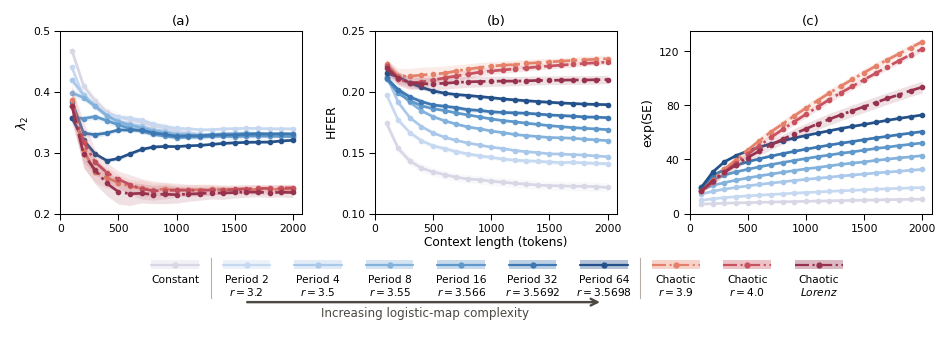

In [4]:
from matplotlib.patches import Rectangle

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
COMBINED_FIGURE_PATH = FIGURE_DIR / "layer_averaged_combined_diagnostics.pdf"

x = context_token_counts.astype(float)


def _plot_context_diagnostic(ax, mean, std):
    for input_idx, data_name in enumerate(input_names):
        y = mean[input_idx].astype(float)
        band = std[input_idx].astype(float)
        style = _diagnostic_line_style(str(data_name))
        zorder = style.get("zorder", 2)
        ax.plot(
            x,
            y,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.3,
            marker=style["marker"],
            markersize=1.7,
            zorder=zorder,
        )
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.15,
            linewidth=0,
            zorder=max(zorder - 0.5, 0),
        )


def _format_combined_axis(ax, ylabel):
    ax.set_ylabel(ylabel, labelpad=1, fontsize=6.0)
    ax.set_xlim(0, 2080)
    ax.set_xticks([0, 500, 1000, 1500, 2000])
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)


complexity_legend_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _complexity_legend_rows(data_name):
    label_map = {
        "Constant sampled": ("Constant", ""),
        "Logistic r=3.2": ("Period 2", r"$r=3.2$"),
        "Logistic r=3.5": ("Period 4", r"$r=3.5$"),
        "Logistic r=3.55": ("Period 8", r"$r=3.55$"),
        "Logistic r=3.566": ("Period 16", r"$r=3.566$"),
        "Logistic r=3.5692": ("Period 32", r"$r=3.5692$"),
        "Logistic r=3.5698": ("Period 64", r"$r=3.5698$"),
        "Logistic r=3.9": ("Chaotic", r"$r=3.9$"),
        "Logistic r=4.0": ("Chaotic", r"$r=4.0$"),
        "Lorenz": ("Chaotic", r"$\mathit{Lorenz}$"),
    }
    return label_map.get(str(data_name), (str(data_name), ""))


def _add_complexity_strip_legend(fig):
    ordered_names = [name for name in complexity_legend_order if name in set(input_names.astype(str))]
    ax_leg = fig.add_axes([0.075, 0.130, 0.910, 0.185])
    ax_leg.set_xlim(-0.55, len(ordered_names) - 0.45)
    ax_leg.set_ylim(0.0, 1.0)
    ax_leg.axis("off")

    spacing_scale = 0.84
    swatch_half_width = 0.28
    swatch_height = 0.115
    legend_center = 0.5 * (len(ordered_names) - 1)

    def _legend_x(raw_x):
        return legend_center + spacing_scale * (float(raw_x) - legend_center)

    for idx, data_name in enumerate(ordered_names):
        legend_x = _legend_x(idx)
        style = _diagnostic_line_style(str(data_name))
        ax_leg.add_patch(
            Rectangle(
                (legend_x - swatch_half_width, 0.7850),
                2.0 * swatch_half_width,
                swatch_height,
                facecolor=style["color"],
                edgecolor="none",
                alpha=0.34,
            )
        )
        ax_leg.plot(
            [legend_x - swatch_half_width, legend_x + swatch_half_width],
            [0.8425, 0.8425],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.05,
            solid_capstyle="round",
        )
        ax_leg.plot(legend_x, 0.8425, marker=style["marker"], markersize=2.0, color=style["color"])
        top_label, bottom_label = _complexity_legend_rows(data_name)
        ax_leg.text(legend_x, 0.660, top_label, ha="center", va="center", fontsize=5.1)
        if bottom_label:
            ax_leg.text(legend_x, 0.505, bottom_label, ha="center", va="center", fontsize=5.1)

    for divider_x in (0.5, 6.5):
        scaled_divider_x = _legend_x(divider_x)
        ax_leg.plot([scaled_divider_x, scaled_divider_x], [0.430, 0.930], color="#B8B0A8", linewidth=0.52)

    ax_leg.annotate(
        "",
        xy=(_legend_x(6.00), 0.375),
        xytext=(_legend_x(0.95), 0.375),
        arrowprops=dict(arrowstyle="->", linewidth=1.15, color="#4C4842"),
    )
    ax_leg.text(
        _legend_x(3.5),
        0.245,
        "Increasing logistic-map complexity",
        ha="center",
        va="center",
        fontsize=5.7,
        color="#4C4842",
    )

with plt.rc_context({
    "font.size": 8.0,
    "axes.labelsize": 5.8,
    "axes.titlesize": 6.4,
    "xtick.labelsize": 5.2,
    "ytick.labelsize": 5.2,
    "legend.fontsize": 8.0,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig = plt.figure(figsize=(6.30, 2.87), dpi=150)
    gs = fig.add_gridspec(
        1,
        3,
        left=0.068,
        right=0.990,
        top=0.830,
        bottom=0.405,
        wspace=0.30,
    )

    ax_fiedler = fig.add_subplot(gs[0, 0])
    ax_hfer = fig.add_subplot(gs[0, 1])
    ax_active = fig.add_subplot(gs[0, 2])

    _plot_context_diagnostic(ax_fiedler, fiedler_mean, fiedler_std)
    _plot_context_diagnostic(ax_hfer, hfer_mean, hfer_std)
    _plot_context_diagnostic(ax_active, active_modes_mean, active_modes_std)

    _format_combined_axis(ax_fiedler, r"$\lambda_2$")
    _format_combined_axis(ax_hfer, r"$\mathrm{HFER}$")
    _format_combined_axis(ax_active, r"$\exp(\mathrm{SE})$")

    ax_fiedler.set_ylim(0.20, 0.50)
    ax_fiedler.set_yticks([0.20, 0.30, 0.40, 0.50])
    ax_fiedler.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax_hfer.set_ylim(0.10, 0.25)
    ax_hfer.set_yticks([0.10, 0.15, 0.20, 0.25])
    ax_hfer.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax_active.set_ylim(0.0, 135.0)
    ax_active.set_yticks([0, 40, 80, 120])
    for ax in (ax_fiedler, ax_hfer, ax_active):
        ax.tick_params(axis="both", which="major", length=2.8, pad=2.0)
    for panel_label, ax in zip(["(a)", "(b)", "(c)"], [ax_fiedler, ax_hfer, ax_active]):
        ax.set_title(panel_label, pad=3.0)

    _add_complexity_strip_legend(fig)
    middle_axis_center = ax_hfer.get_position().x0 + 0.5 * ax_hfer.get_position().width
    fig.supxlabel("Context length (tokens)", x=middle_axis_center, y=0.325, fontsize=5.8)
    fig.align_ylabels([ax_fiedler, ax_hfer, ax_active])
    fig.savefig(COMBINED_FIGURE_PATH, format="pdf", bbox_inches="tight", pad_inches=0.02)
    print(f"Saved {COMBINED_FIGURE_PATH}")
    plt.show()


Saved figures/layer_averaged_hfer_cutoffs.pdf


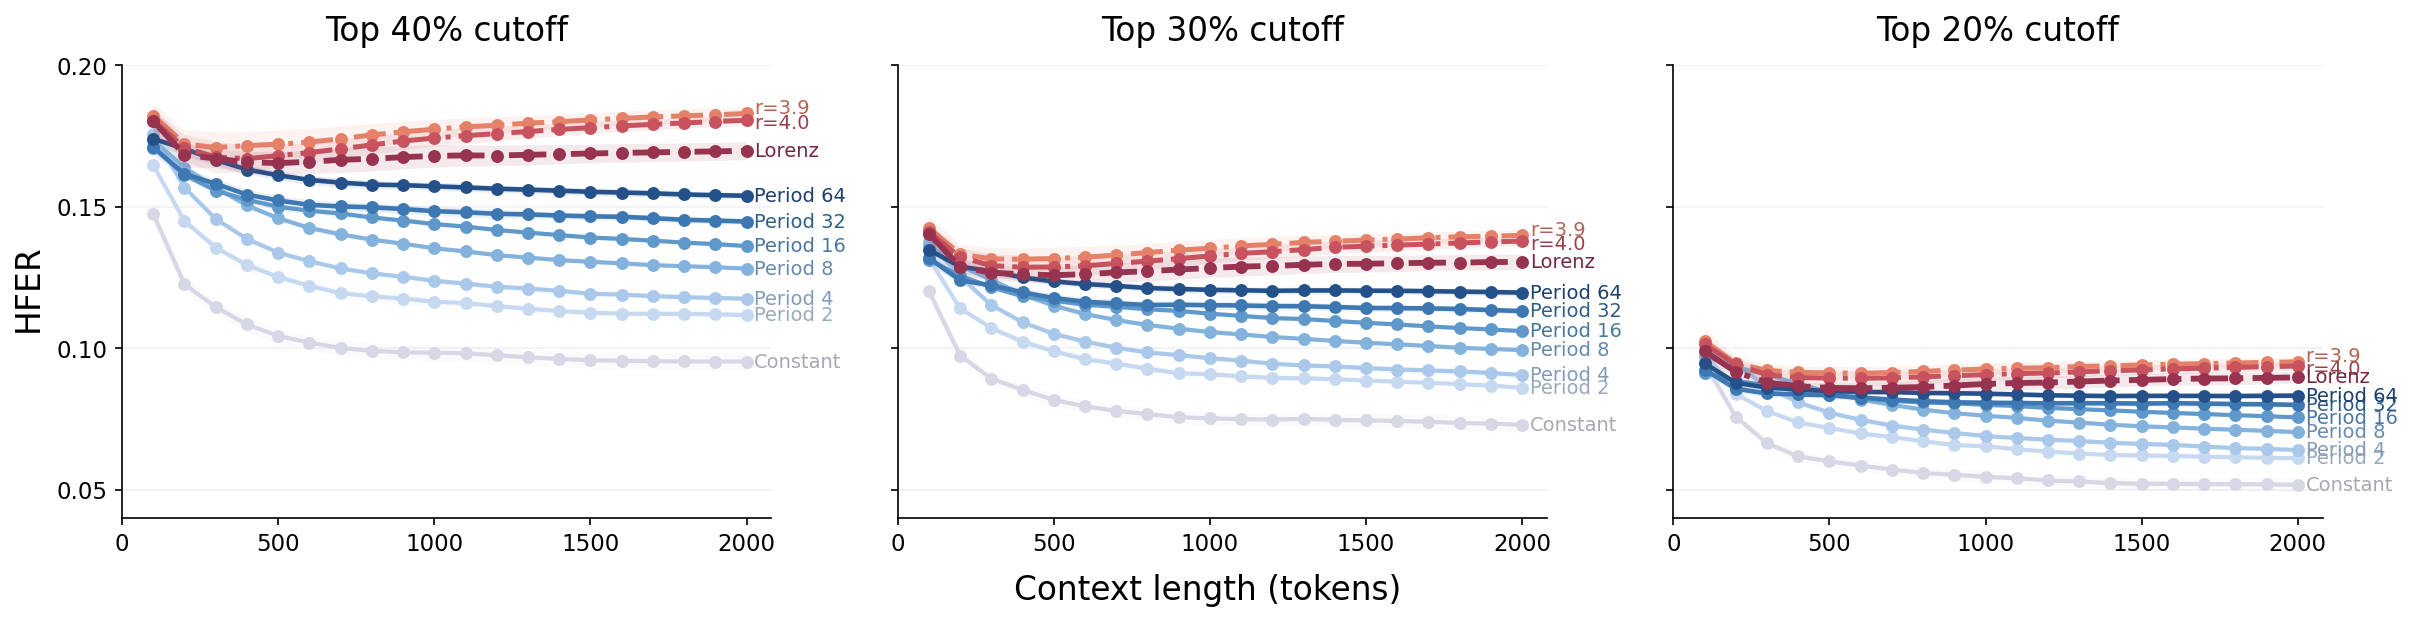

In [5]:
# Compare selected HFER high-frequency cutoffs
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
HFER_CUTOFF_FIGURE_PATH = FIGURE_DIR / "layer_averaged_hfer_cutoffs.pdf"

HFER_CUTOFF_FRACTIONS_TO_PLOT = np.asarray([0.40, 0.30, 0.20], dtype=float)
HFER_CUTOFF_Y_TICKS = np.asarray([0.05, 0.10, 0.15, 0.20], dtype=float)
HFER_CUTOFF_X_TICKS = np.asarray([0, 500, 1000, 1500, 2000], dtype=int)
HFER_CUTOFF_AXIS_LABEL_SIZE = 15.73
HFER_CUTOFF_TICK_LABEL_SIZE = 11.0
HFER_CUTOFF_MARKER_SIZE = 5.2
HFER_CUTOFF_ENDPOINT_LABEL_DARKENING = 0.78


def hfer_tail_index_from_fraction(tail_fraction):
    matches = np.flatnonzero(np.isclose(hfer_tail_fractions, float(tail_fraction)))
    if matches.size != 1:
        raise ValueError(f"Requested HFER tail fraction {tail_fraction} is not stored.")
    return int(matches[0])


def hfer_cutoff_endpoint_label_offset(data_name):
    if str(data_name) == "Logistic r=3.9":
        return 0.002
    if str(data_name) == "Logistic r=4.0":
        return -0.001
    return _endpoint_label_offset(str(data_name))


hfer_cutoff_tail_indices = np.asarray(
    [hfer_tail_index_from_fraction(tail_fraction) for tail_fraction in HFER_CUTOFF_FRACTIONS_TO_PLOT],
    dtype=int,
)
hfer_cutoff_mean_for_limits = hfer_tail_energy_mean[:, :, hfer_cutoff_tail_indices]
hfer_cutoff_std_for_limits = hfer_tail_energy_std[:, :, hfer_cutoff_tail_indices]
hfer_cutoff_y_lower = np.nanmin(hfer_cutoff_mean_for_limits - hfer_cutoff_std_for_limits)
hfer_cutoff_y_upper = np.nanmax(hfer_cutoff_mean_for_limits + hfer_cutoff_std_for_limits)
hfer_cutoff_y_pad = 0.06 * (hfer_cutoff_y_upper - hfer_cutoff_y_lower)
hfer_cutoff_y_min = max(0.0, np.floor(100 * (hfer_cutoff_y_lower - hfer_cutoff_y_pad)) / 100)
hfer_cutoff_y_max = np.ceil(100 * (hfer_cutoff_y_upper + hfer_cutoff_y_pad)) / 100

fig, axes = plt.subplots(
    1,
    len(HFER_CUTOFF_FRACTIONS_TO_PLOT),
    figsize=(16.2, 4.6),
    dpi=150,
    sharex=True,
    sharey=True,
)
axes = np.ravel(np.atleast_1d(axes))
endpoint_label_x_offset = 25
x = context_token_counts.astype(float)

for ax_idx, (ax, tail_fraction) in enumerate(zip(axes, HFER_CUTOFF_FRACTIONS_TO_PLOT)):
    tail_idx = hfer_tail_index_from_fraction(tail_fraction)
    hfer_tail_mean = hfer_tail_energy_mean[:, :, tail_idx]
    hfer_tail_std = hfer_tail_energy_std[:, :, tail_idx]
    cutoff_percent = int(round(100 * float(tail_fraction)))
    panel_title = f"Top {cutoff_percent}% cutoff"

    for input_idx, data_name in enumerate(input_names):
        y = hfer_tail_mean[input_idx].astype(float)
        band = hfer_tail_std[input_idx].astype(float)
        style = _metric_line_style(str(data_name), ensemble=True)
        style["markersize"] = HFER_CUTOFF_MARKER_SIZE
        ax.plot(x, y, **style)
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.10,
            linewidth=0,
            zorder=max(style.get("zorder", 2) - 0.5, 0),
        )
        _add_endpoint_label(
            ax,
            x,
            y,
            _endpoint_label_text(str(data_name)),
            color=_darken_color(style["color"], HFER_CUTOFF_ENDPOINT_LABEL_DARKENING),
            y_offset=hfer_cutoff_endpoint_label_offset(str(data_name)),
            x_offset=endpoint_label_x_offset,
            fontsize=9.35,
        )

    _format_context_axis(
        ax,
        r"$\mathrm{HFER}$" if ax_idx == 0 else "",
        panel_title,
    )
    ax.set_xlabel("")
    ax.set_xticks(HFER_CUTOFF_X_TICKS)
    ax.set_ylim(hfer_cutoff_y_min, hfer_cutoff_y_max)
    ax.set_yticks(HFER_CUTOFF_Y_TICKS)
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.tick_params(axis="both", which="major", labelsize=HFER_CUTOFF_TICK_LABEL_SIZE)
    ax.tick_params(axis="y", labelleft=(ax_idx == 0))
    if ax_idx == 0:
        ax.set_ylabel(r"$\mathrm{HFER}$", fontsize=HFER_CUTOFF_AXIS_LABEL_SIZE)
    ax.set_title(panel_title, fontsize=HFER_CUTOFF_AXIS_LABEL_SIZE, pad=12)

fig.supxlabel("Context length (tokens)", y=0.11, fontsize=HFER_CUTOFF_AXIS_LABEL_SIZE)
plt.tight_layout(rect=(0, 0.070, 1, 1), w_pad=2.0)
fig.savefig(HFER_CUTOFF_FIGURE_PATH, format="pdf", bbox_inches="tight", pad_inches=0.02)
print(f"Saved {HFER_CUTOFF_FIGURE_PATH}")
plt.show()


Saved figures/layer_averaged_low_end_laplacian_spectrum.pdf


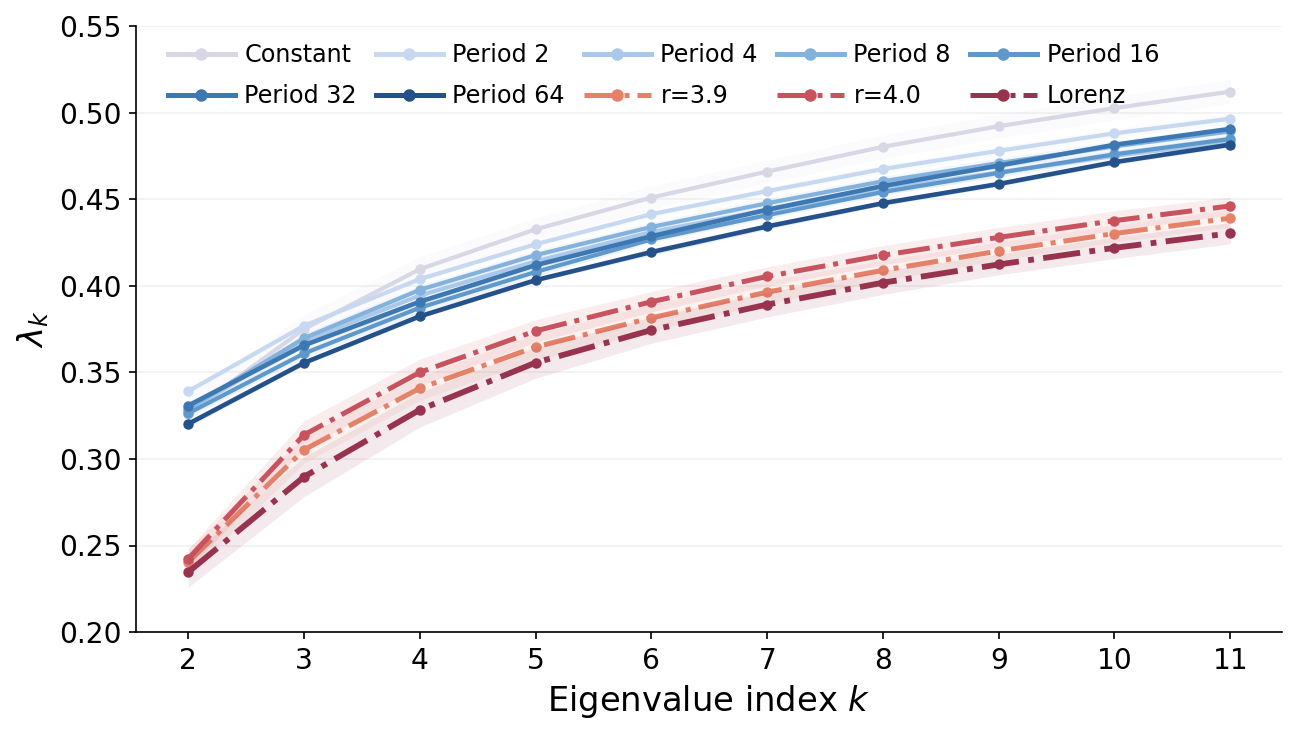

In [6]:
# Plot the low-end spectrum at the largest cached context
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
LOW_SPECTRUM_FIGURE_PATH = FIGURE_DIR / "layer_averaged_low_end_laplacian_spectrum.pdf"

EIGENVALUE_DISTRIBUTION_CONTEXT_INDEX = -1

context_idx = int(EIGENVALUE_DISTRIBUTION_CONTEXT_INDEX)
selected_context_tokens = int(context_token_counts[context_idx])
lambda_indices = fiedler_lsym_low_spectrum_lambda_indices.astype(int)

spectrum_y_lower = np.nanmin(
    fiedler_lsym_low_spectrum_mean[:, context_idx, :] - fiedler_lsym_low_spectrum_std[:, context_idx, :]
)
spectrum_y_upper = np.nanmax(
    fiedler_lsym_low_spectrum_mean[:, context_idx, :] + fiedler_lsym_low_spectrum_std[:, context_idx, :]
)
spectrum_y_pad = 0.06 * (spectrum_y_upper - spectrum_y_lower)
spectrum_y_min = max(0.0, np.floor(20 * (spectrum_y_lower - spectrum_y_pad)) / 20)
spectrum_y_max = np.ceil(20 * (spectrum_y_upper + spectrum_y_pad)) / 20

fig, ax = plt.subplots(1, 1, figsize=(8.8, 5.0), dpi=150)

for input_idx, data_name in enumerate(input_names):
    y = fiedler_lsym_low_spectrum_mean[input_idx, context_idx].astype(float)
    band = fiedler_lsym_low_spectrum_std[input_idx, context_idx].astype(float)
    style = _metric_line_style(str(data_name), ensemble=True)
    ax.plot(lambda_indices, y, **style)
    ax.fill_between(
        lambda_indices,
        y - band,
        y + band,
        color=style["color"],
        alpha=0.10,
        linewidth=0,
        zorder=max(style.get("zorder", 2) - 0.5, 0),
    )

LOW_SPECTRUM_FONT_SCALE = 1.35
_add_two_row_fiedler_legend(ax, font_scale=LOW_SPECTRUM_FONT_SCALE)
ax.set_xlabel(r"Eigenvalue index $k$", fontsize=12.0 * LOW_SPECTRUM_FONT_SCALE)
ax.set_ylabel(r"$\lambda_k$", fontsize=12.0 * LOW_SPECTRUM_FONT_SCALE)
ax.set_xticks(lambda_indices)
ax.tick_params(axis="both", which="major", labelsize=10.0 * LOW_SPECTRUM_FONT_SCALE)
ax.set_ylim(spectrum_y_min, spectrum_y_max)
ax.set_axisbelow(True)
ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
fig.savefig(LOW_SPECTRUM_FIGURE_PATH, format="pdf", bbox_inches="tight", pad_inches=0.02)
print(f"Saved {LOW_SPECTRUM_FIGURE_PATH}")
plt.show()
